# Multimodal Neonatal Jaundice Prediction with 2D CNN

This notebook demonstrates a complete pipeline for multimodal neonatal jaundice prediction using a 2D CNN for image data and an MLP for clinical data. Each section corresponds to a logical part of the workflow: imports, preprocessing, data loading, data generator, model definition, training, and saving.

In [7]:
# Imports and configuration
import os
import numpy as np
import pandas as pd
import cv2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Concatenate
from tensorflow.keras.utils import Sequence
from sklearn.model_selection import train_test_split

# Config
IMG_SIZE = (128, 128)
IMG_DIR = '../images'  # Adjust if needed
CLINICAL_CSV = '../NeoJaundice/chd_jaundice_published_2.csv'  # Adjust if needed
BATCH_SIZE = 16
EPOCHS = 10

## Image Preprocessing
This function loads an image, applies a center crop (as a placeholder for ROI extraction), resizes, and normalizes it.

In [8]:
def preprocess_image(img_path):
    img = cv2.imread(img_path)
    if img is None:
        raise FileNotFoundError(f"Image not found: {img_path}")
    # Example: simple center crop (replace with ROI extraction/color calibration as needed)
    h, w, _ = img.shape
    min_dim = min(h, w)
    start_h = (h - min_dim) // 2
    start_w = (w - min_dim) // 2
    img = img[start_h:start_h+min_dim, start_w:start_w+min_dim]
    img = cv2.resize(img, IMG_SIZE)
    img = img / 255.0
    return img

## Clinical Data Loading and Image Matching
This section loads the clinical CSV, renames columns, and matches each patient to an image file.

In [9]:
def load_clinical_data():
    df = pd.read_csv(CLINICAL_CSV)
    # Map columns as needed (example: patient_id, blood(mg/dL), Treatment)
    df = df.rename(columns={
        'patient_id': 'Infant_ID',
        'blood(mg/dL)': 'TSB',
        'Treatment': 'Risk_Class'
    })
    return df

def get_image_path(infant_id):
    # Example: expects images named like 0001-1.jpg, 0001-2.jpg, etc.
    for suffix in ['-1.jpg', '-2.jpg', '-3.jpg']:
        path = os.path.join(IMG_DIR, f"{str(infant_id).zfill(4)}{suffix}")
        if os.path.exists(path):
            return path
    return None

## Data Generator
This class yields batches of (image, clinical) input pairs and their corresponding regression and classification targets.

In [10]:
class DataGen(Sequence):
    def __init__(self, df, batch_size=BATCH_SIZE, shuffle=True):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.df))
        self.on_epoch_end()
    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))
    def __getitem__(self, idx):
        batch_idx = self.indexes[idx*self.batch_size:(idx+1)*self.batch_size]
        batch = self.df.iloc[batch_idx]
        X_img = []
        X_clin = []
        y_reg = []
        y_cls = []
        for _, row in batch.iterrows():
            img_path = get_image_path(row['Infant_ID'])
            if img_path is None:
                continue
            img = preprocess_image(img_path)
            X_img.append(img)
            # Example: use 3 clinical features (customize as needed)
            X_clin.append([row['TSB'], row.get('feature2', 0), row.get('feature3', 0)])
            y_reg.append(row['TSB'])
            # Example: risk class as integer (0,1,2)
            y_cls.append(int(row['Risk_Class']))
        return (
            {"visual_input": np.array(X_img), "clinical_input": np.array(X_clin)},
            {"tsb_regression_output": np.array(y_reg), "risk_classification_output": np.array(y_cls)}
        )
    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)

## Model Definition
This function builds a multimodal model with a 2D CNN for images and an MLP for clinical data, fusing both branches for dual output.

In [11]:
def build_model():
    # Visual branch (2D CNN)
    visual_input = Input(shape=(*IMG_SIZE, 3), name='visual_input')
    x = Conv2D(32, (3,3), activation='relu', padding='same')(visual_input)
    x = MaxPooling2D((2,2))(x)
    x = Conv2D(64, (3,3), activation='relu', padding='same')(x)
    x = MaxPooling2D((2,2))(x)
    x = Flatten()(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.5)(x)
    visual_embedding = Dense(64, activation='relu')(x)
    # Clinical branch (MLP)
    clinical_input = Input(shape=(3,), name='clinical_input')
    c = Dense(32, activation='relu')(clinical_input)
    c = Dropout(0.3)(c)
    clinical_embedding = Dense(16, activation='relu')(c)
    # Fusion
    fusion = Concatenate()([visual_embedding, clinical_embedding])
    f = Dense(64, activation='relu')(fusion)
    f = Dropout(0.3)(f)
    # Outputs
    tsb_regression = Dense(1, name='tsb_regression_output')(f)
    risk_classification = Dense(3, activation='softmax', name='risk_classification_output')(f)
    model = Model(inputs=[visual_input, clinical_input], outputs=[tsb_regression, risk_classification])
    model.compile(
        optimizer='adam',
        loss={'tsb_regression_output': 'mse', 'risk_classification_output': 'sparse_categorical_crossentropy'},
        metrics={'tsb_regression_output': 'mae', 'risk_classification_output': 'accuracy'}
    )
    return model

## Training and Saving the Model
This section loads the data, splits into train/validation, creates generators, trains the model, and saves it.

In [12]:
# Load clinical data and match images
df = load_clinical_data()
df['img_path'] = df['Infant_ID'].apply(get_image_path)
df = df[df['img_path'].notnull()]
# Split
df_train, df_val = train_test_split(df, test_size=0.2, random_state=42)
train_gen = DataGen(df_train)
val_gen = DataGen(df_val, shuffle=False)
# Build model
model = build_model()
model.summary()
# Train
model.fit(train_gen, validation_data=val_gen, epochs=EPOCHS)
# Save
model.save('2dcnn_multimodal_model.h5')
print('Training complete. Model saved as 2dcnn_multimodal_model.h5')

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ visual_input        │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │        896 │ visual_input[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 64, 64,    │          0 │ conv2d_2[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 65536)     │          0 │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clinical_input      │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 128)       │  8,388,736 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 32)        │        128 │ clinical_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 32)        │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 64)        │      8,256 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 16)        │        528 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 80)        │          0 │ dense_6[0][0],    │
│ (Concatenate)       │                   │            │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 64)        │      5,184 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 64)        │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tsb_regression_out… │ (None, 1)         │         65 │ dropout_5[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ risk_classificatio… │ (None, 3)         │        195 │ dropout_5[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,422,484 (32.13 MB)

 Trainable params: 8,422,484 (32.13 MB)

 Non-trainable params: 0 (0.00 B)

...

/Users/shubhbhateja/College/minor_project/.venv/lib/python3.13/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


111/112 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 34.2536 - risk_classification_output_accuracy: 0.4095 - risk_classification_output_loss: 2.2090 - tsb_regression_output_loss: 31.9948 - tsb_regression_output_mae: 4.3135

/Users/shubhbhateja/College/minor_project/.venv/lib/python3.13/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


112/112 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - loss: 18.0531 - risk_classification_output_accuracy: 0.5011 - risk_classification_output_loss: 1.4377 - tsb_regression_output_loss: 16.6240 - tsb_regression_output_mae: 3.0248 - val_loss: 2.6499 - val_risk_classification_output_accuracy: 0.6689 - val_risk_classification_output_loss: 0.5244 - val_tsb_regression_output_loss: 2.1257 - val_tsb_regression_output_mae: 1.1174
Epoch 2/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 6s 57ms/step - loss: 6.4895 - risk_classification_output_accuracy: 0.6812 - risk_classification_output_loss: 0.7055 - tsb_regression_output_loss: 5.7788 - tsb_regression_output_mae: 1.8223 - val_loss: 2.0692 - val_risk_classification_output_accuracy: 0.9664 - val_risk_classification_output_loss: 0.4053 - val_tsb_regression_output_loss: 1.6644 - val_tsb_regression_output_mae: 1.0077
Epoch 3/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 62ms/step - loss: 5.1177 - risk_classification_output_accuracy: 0.7041 - risk_classification_output_loss: 0.6060 - t

Training complete. Model saved as 2dcnn_multimodal_model.h5


## Visualize Training Results
Plot the training and validation loss and metrics to evaluate model performance.

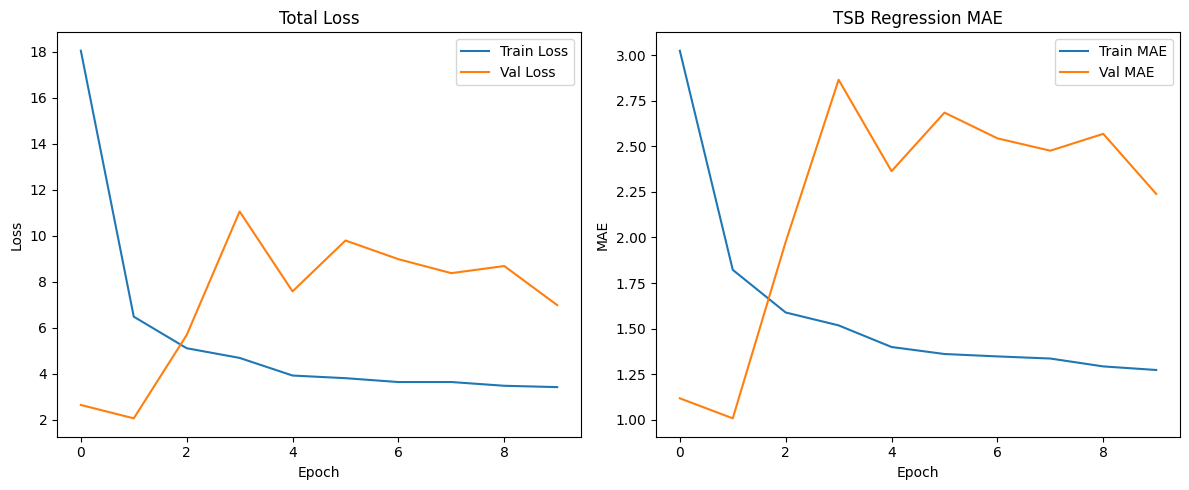

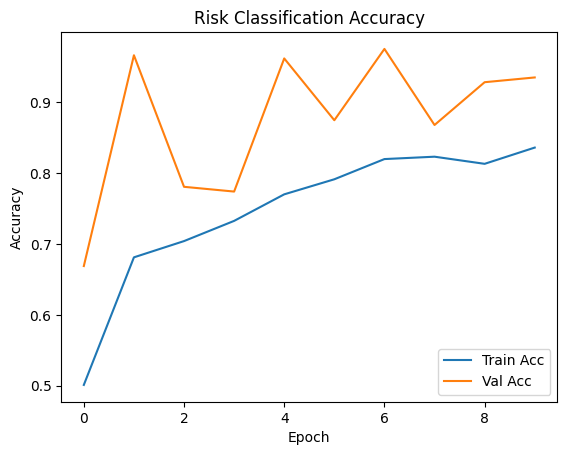

In [13]:
# Plot training history
import matplotlib.pyplot as plt

# If you saved the history object, use it directly. Otherwise, get from model.history
history = model.history.history if hasattr(model, 'history') else None

if history:
    # Plot loss
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history['loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Val Loss')
    plt.title('Total Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    # Plot regression MAE
    plt.subplot(1, 2, 2)
    plt.plot(history['tsb_regression_output_mae'], label='Train MAE')
    plt.plot(history['val_tsb_regression_output_mae'], label='Val MAE')
    plt.title('TSB Regression MAE')
    plt.xlabel('Epoch')
    plt.ylabel('MAE')
    plt.legend()
    plt.tight_layout()
    plt.show()
    # Plot classification accuracy
    plt.figure()
    plt.plot(history['risk_classification_output_accuracy'], label='Train Acc')
    plt.plot(history['val_risk_classification_output_accuracy'], label='Val Acc')
    plt.title('Risk Classification Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()
else:
    print('No training history found. Please ensure you save the history object from model.fit().')